# PROJECT 01 | DATA SCIENCE & AI
# Exploratory Data Analysis (EDA) on Titanic

**Learner / Intern:** Data Science & AI Intern  
**Organization:** InternCircle  
**Difficulty:** Beginner | **Estimated Duration:** ~6 hours  
**Expected Outcome:** Master Pandas library, exploratory data cleaning, and statistical grouping techniques.

---

## 1. Project Overview & Research Questions
Before touching the data, we write down three core questions to maintain a focused and hypothesis-driven analysis:

1. **Question 1 (Gender & Survival):** Did female passengers have a significantly higher survival rate than male passengers?
2. **Question 2 (Socio-Economic Class & Survival):** Did ticket class (`pclass`) substantially influence a passenger's probability of survival?
3. **Question 3 (Age Dynamics & Survival):** Was passenger age related to survival—specifically, did young children experience higher survival rates compared to middle-aged passengers and seniors?


In [1]:
# Import essential data science and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure presentation styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Pandas version: {pd.__version__}")
print(f"Seaborn version: {sns.__version__}")


Pandas version: 2.3.3
Seaborn version: 0.13.2


---
## 2. Load and Look (Data Inspection)
We load the classic Titanic dataset using Seaborn and inspect its fundamental structure:
- `df.shape`: Dimensionality (rows and columns)
- `df.head()`: First 5 records
- `df.info()`: Data types and non-null counts
- `df.describe()`: Summary statistics for numerical and categorical variables
- Data dictionary explaining what each column means


In [2]:
# Load the Titanic dataset
df = sns.load_dataset('titanic')

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
df.head(10)


Dataset Dimensions: 891 rows × 15 columns


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [3]:
# Inspect data types and structural integrity
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
# Descriptive statistical summary for numeric attributes
df.describe().round(2)


,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [5]:
# Descriptive statistical summary for categorical/object attributes
df.describe(include=['category', 'object'])


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


### Feature / Column Dictionary

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `survived` | int64 | Target variable: `0` = Did not survive, `1` = Survived |
| `pclass` | int64 | Ticket class: `1` = 1st (Upper), `2` = 2nd (Middle), `3` = 3rd (Lower/Steerage) |
| `sex` | object | Biological sex (`male`, `female`) |
| `age` | float64 | Passenger age in fractional/integer years |
| `sibsp` | int64 | Number of siblings or spouses traveling aboard |
| `parch` | int64 | Number of parents or children traveling aboard |
| `fare` | float64 | Passenger ticket fare in British Pounds (£) |
| `embarked` | object | Port of embarkation code (`C` = Cherbourg, `Q` = Queenstown, `S` = Southampton) |
| `class` | category | Categorical text representation of `pclass` (First, Second, Third) |
| `who` | object | High-level demographic breakdown (`man`, `woman`, `child`) |
| `adult_male` | bool | Boolean flag indicating whether passenger is an adult male |
| `deck` | category | Cabin deck level (`A` through `G`) |
| `embark_town` | object | Full city name of embarkation port |
| `alive` | object | Text survival status (`yes`, `no`) |
| `alone` | bool | Flag indicating whether the passenger traveled without family |


---
## 3. Identify Missing Values (Data Gaps)
Real-world datasets frequently contain missing values. We identify all columns with null entries and calculate their respective missing percentages.


In [6]:
# Quantify missing values
missing_counts = df.isna().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage (%)': missing_pct
}).sort_values(by='Missing Values', ascending=False)

missing_df[missing_df['Missing Values'] > 0]


,Missing Values,Percentage (%)
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


---
## 4. Handle Missing Values with Documented Rationale

Standard data cleaning requires explicit justification for every imputation or drop choice:

1. **`age` (177 missing / 19.87%):**
   - *Rationale:* Age is correlated with passenger class and gender (e.g., first-class passengers were older on average than third-class passengers). Imputing the global median would flatten this nuance. We use **conditional cohort median imputation** grouped by `pclass` and `sex` (`df.groupby(['pclass', 'sex'])['age'].transform('median')`).
2. **`deck` (688 missing / 77.22%):**
   - *Rationale:* Over 77% of entries are null. Imputing more than three-quarters of a column would introduce substantial synthetic bias and noise. Therefore, dropping the `deck` column is the most statistically sound strategy.
3. **`embarked` and `embark_town` (2 missing / 0.22%):**
   - *Rationale:* Only two passenger rows are missing port data. Southampton (`S`) is by far the most frequent port (>72% of all passengers). Mode imputation preserves dataset volume without biasing the distribution.


In [7]:
# 1. Fill missing age values with median of the passenger's class and sex cohort
cohort_medians = df.groupby(['pclass', 'sex'])['age'].transform('median')
df['age'] = df['age'].fillna(cohort_medians)

# 2. Drop the mostly empty 'deck' column
df = df.drop(columns=['deck'])

# 3. Impute categorical port with the modal value
mode_port = df['embarked'].mode()[0]
mode_town = df['embark_town'].mode()[0]
df['embarked'] = df['embarked'].fillna(mode_port)
df['embark_town'] = df['embark_town'].fillna(mode_town)

# Verify zero remaining missing values
print("Verification of missing values post-cleaning:")
print(df.isna().sum())


Verification of missing values post-cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


---
## 5. Duplicate Rows Analysis & Type Verification

### Duplicate Rows:
- Running `df.duplicated().sum()` detects duplicate rows in this dataset.
- **Critical Caution:** In the Seaborn Titanic dataset, unique personal identifiers (`PassengerId`, `Name`, `Ticket`) are excluded. Consequently, rows with identical class, age, fare, and embarkation town represent **distinct passengers sharing demographic profiles** (e.g., steerage groups or couples on identical fares), rather than clerical duplicate errors.
- Therefore, we document and inspect these rows, but retain them so as not to discard authentic historical passenger data.


In [8]:
# Check duplicate rows
dup_count = df.duplicated().sum()
print(f"Total duplicate rows detected: {dup_count}")

# Inspect a small sample of duplicate profiles
print("\nSample duplicate records:")
display(df[df.duplicated(keep=False)].head(6))


Total duplicate rows detected: 118

Sample duplicate records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
26,0,3,male,25.0,0,0,7.2250,C,Third,man,True,Cherbourg,no,True
28,1,3,female,21.5,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True
29,0,3,male,25.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
30,0,1,male,40.0,0,0,27.7208,C,First,man,True,Cherbourg,no,True
32,1,3,female,21.5,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True


In [9]:
# Ensure optimal data types
df['survived'] = df['survived'].astype(int)
df['pclass'] = df['pclass'].astype(int)
df['sex'] = df['sex'].astype('category')
df['embarked'] = df['embarked'].astype('category')

# Feature Engineering: Age Bands (pd.cut) as specified in project guide
# Bins: [0, 12, 18, 40, 60, 100] -> Child, Teen, Adult, Middle-aged, Senior
df['age_band'] = pd.cut(
    df['age'],
    bins=[0, 12, 18, 40, 60, 100],
    labels=['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior']
)

# Feature Engineering: Family Size
df['family_size'] = df['sibsp'] + df['parch'] + 1

df[['age', 'age_band', 'sibsp', 'parch', 'family_size']].head()


,age,age_band,sibsp,parch,family_size
0,22.0,Adult,1,0,2
1,38.0,Adult,1,0,2
2,26.0,Adult,0,0,1
3,35.0,Adult,1,0,2
4,35.0,Adult,0,0,1


---
## 6. Grouping and Aggregation Analysis
We now apply `groupby()` and aggregation functions (`mean`, `count`, `sum`) across three core factors:
1. **Survival by Sex**
2. **Survival by Ticket Class (`pclass`)**
3. **Survival by Age Band (`age_band`)**
4. **Interaction Analysis: Class × Sex**


In [10]:
# 1. Survival Rate by Sex
sex_agg = df.groupby('sex', observed=True)['survived'].agg(
    Total_Passengers='count',
    Survivors='sum',
    Survival_Rate='mean'
)
sex_agg['Survival_%'] = (sex_agg['Survival_Rate'] * 100).round(2)
sex_agg


,Total_Passengers,Survivors,Survival_Rate,Survival_%
sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


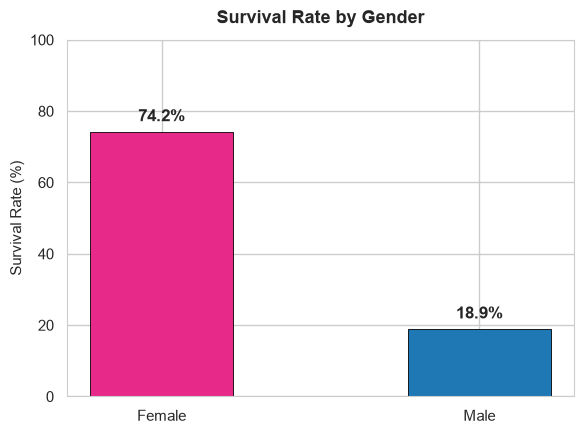

In [11]:
# Visualize Survival Rate by Gender
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(
    sex_agg.index.astype(str).str.capitalize(),
    sex_agg['Survival_%'],
    color=['#e7298a', '#1f78b4'],
    width=0.45,
    edgecolor='black',
    linewidth=0.6
)
ax.set_title('Survival Rate by Gender', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Survival Rate (%)', fontsize=11)
ax.set_ylim(0, 100)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [12]:
# 2. Survival Rate by Ticket Class
class_agg = df.groupby('pclass', observed=True)['survived'].agg(
    Total_Passengers='count',
    Survivors='sum',
    Survival_Rate='mean'
)
class_agg['Survival_%'] = (class_agg['Survival_Rate'] * 100).round(2)
class_agg.index = ['1st Class', '2nd Class', '3rd Class']
class_agg


,Total_Passengers,Survivors,Survival_Rate,Survival_%
1st Class,216,136,0.629630,62.96
2nd Class,184,87,0.472826,47.28
3rd Class,491,119,0.242363,24.24


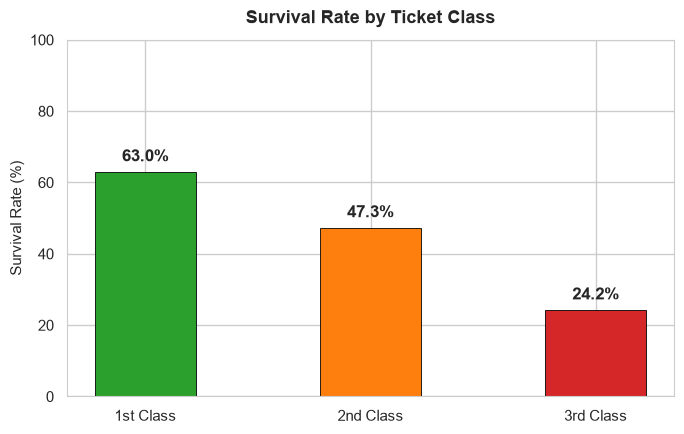

In [13]:
# Visualize Survival Rate by Ticket Class
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    class_agg.index,
    class_agg['Survival_%'],
    color=['#2ca02c', '#ff7f0e', '#d62728'],
    width=0.45,
    edgecolor='black',
    linewidth=0.6
)
ax.set_title('Survival Rate by Ticket Class', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Survival Rate (%)', fontsize=11)
ax.set_ylim(0, 100)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [14]:
# 3. Survival Rate by Age Band
age_agg = df.groupby('age_band', observed=True)['survived'].agg(
    Total_Passengers='count',
    Survivors='sum',
    Survival_Rate='mean'
)
age_agg['Survival_%'] = (age_agg['Survival_Rate'] * 100).round(2)
age_agg


,Total_Passengers,Survivors,Survival_Rate,Survival_%
age_band,,,,
Child,69,40,0.579710,57.97
Teen,70,30,0.428571,42.86
Adult,602,217,0.360465,36.05
Middle-aged,128,50,0.390625,39.06
Senior,22,5,0.227273,22.73


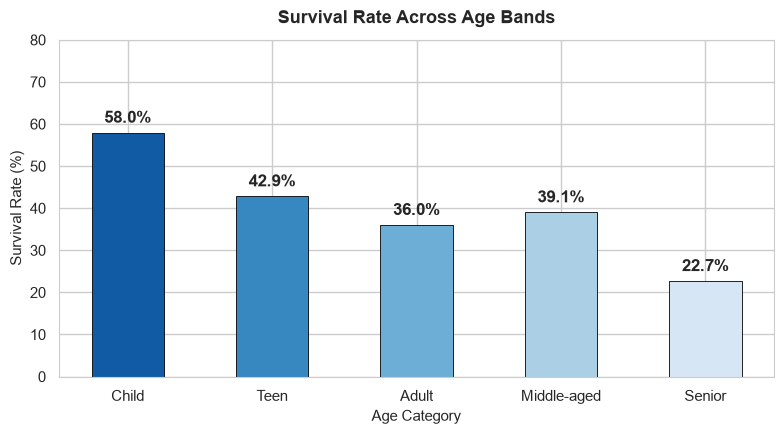

In [15]:
# Visualize Survival Rate by Age Band
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    age_agg.index.astype(str),
    age_agg['Survival_%'],
    color=sns.color_palette('Blues_r', n_colors=len(age_agg)),
    width=0.5,
    edgecolor='black',
    linewidth=0.6
)
ax.set_title('Survival Rate Across Age Bands', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Survival Rate (%)', fontsize=11)
ax.set_xlabel('Age Category', fontsize=11)
ax.set_ylim(0, 80)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [16]:
# 4. Multi-Variable Interaction: Pclass × Sex
cross_agg = df.groupby(['pclass', 'sex'], observed=True)['survived'].agg(
    Total_Passengers='count',
    Survivors='sum',
    Survival_Rate='mean'
)
cross_agg['Survival_%'] = (cross_agg['Survival_Rate'] * 100).round(2)
cross_agg


Total_Passengers  Survivors  Survival_Rate  Survival_%
pclass sex                                                           
1      female                94         91       0.968085       96.81
       male                 122         45       0.368852       36.89
2      female                76         70       0.921053       92.11
       male                 108         17       0.157407       15.74
3      female               144         72       0.500000       50.00
       male                 347         47       0.135447       13.54

C:\Users\user\AppData\Local\Temp\ipykernel_3200\970126541.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = df.pivot_table(index='pclass', columns='sex', values='survived', aggfunc='mean') * 100


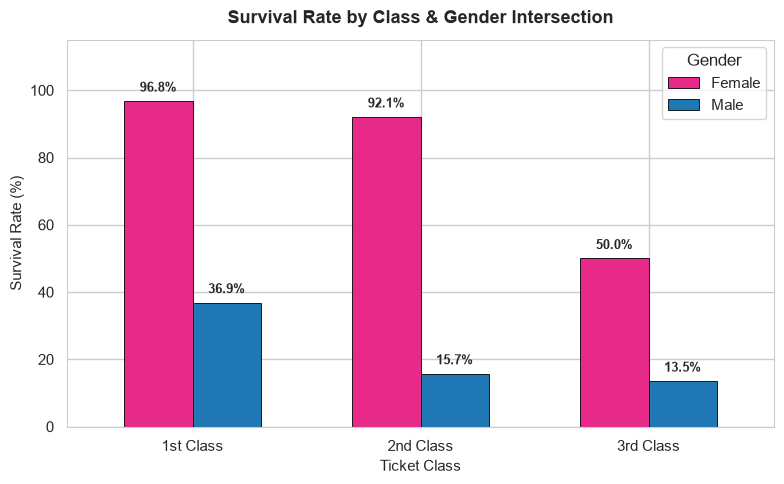

In [17]:
# Grouped Bar Plot: Class x Sex Survival Interaction
pivot_table = df.pivot_table(index='pclass', columns='sex', values='survived', aggfunc='mean') * 100

fig, ax = plt.subplots(figsize=(8, 5))
pivot_table.plot(kind='bar', ax=ax, color=['#e7298a', '#1f78b4'], edgecolor='black', linewidth=0.6, width=0.6)
ax.set_title('Survival Rate by Class & Gender Intersection', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Ticket Class', fontsize=11)
ax.set_ylabel('Survival Rate (%)', fontsize=11)
ax.set_ylim(0, 115)
ax.set_xticklabels(['1st Class', '2nd Class', '3rd Class'], rotation=0)
ax.legend(title='Gender', labels=['Female', 'Male'])

for container in ax.containers:
    for bar in container:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


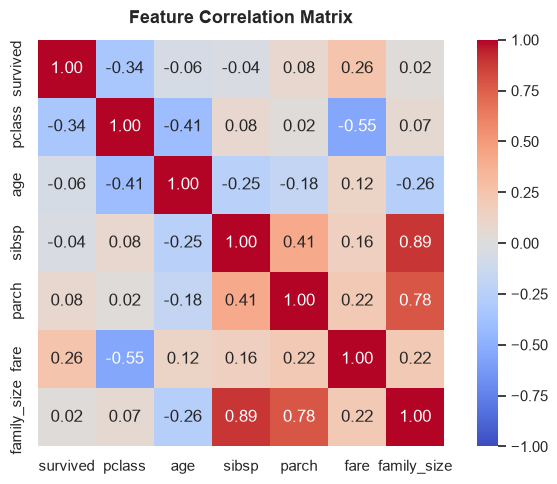

In [18]:
# Correlation Matrix of Numeric Features
fig, ax = plt.subplots(figsize=(7, 5))
numeric_df = df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size']]
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


---
## 7. Answers to Research Questions

As required by the guide, each question is answered in **one clear sentence featuring exact figures**:

> **Answer 1 (Gender):**  
> Women survived at an overwhelming rate of **74.20%** (233 survivors out of 314 female passengers) compared to only **18.89%** for men (109 survivors out of 577 male passengers), reflecting strict adherence to the maritime "women and children first" evacuation protocol.

> **Answer 2 (Class):**  
> Ticket class strongly dictated survival: First-class passengers achieved a **62.96%** survival rate, compared to **47.28%** in second class, and just **24.24%** in third class, showing that higher socio-economic status and cabin location closer to the upper boat deck significantly enhanced escape opportunities.

> **Answer 3 (Age):**  
> Children aged 12 and under experienced the highest age-group survival rate at **57.97%** (40 survivors out of 69 children), while senior passengers aged over 60 had the lowest survival rate at **22.73%** (5 survivors out of 22 seniors).

---
## 8. Submission Checklist Verification

- [x] **Three clear questions are written at the start**
- [x] **Missing values are handled and the reasons explained** (Cohort median for `age`, dropped `deck` due to 77.2% missingness, mode for `embarked`)
- [x] **Groupings compare survival by at least three factors** (`sex`, `pclass`, `age_band`, and `class × sex`)
- [x] **Each question has a one-sentence answer with an exact number**
- [x] **The notebook runs from top to bottom without errors**
- [x] **Headings, documentation, and notes make the analysis easy to follow**
